# DNN Assignment 2 — Problem 2: Transformer from scratch

Contents: (1) scaled dot-product attention, (2) multi-head attention, sinusoidal positional encoding and the pre-LayerNorm encoder block with parameter count, (3) Task A encoder classifier on HAR, (4) Task B character-level causal language model, (5) analysis and ablations (heatmaps, heads, no causal mask, time and memory against context length), (6) bonus: key-value cache and LSTM versus Transformer on the character task.

**Assumptions (mention them in the report).**
- The brief's "Individualisation" variants table was not released, so I use the same choices as Problem 1: seeds `(1, 42, 123)`, `d = 128` for the language model, `d = 64` for the HAR encoder.
- The instructor's 3-token attention example was not supplied, so I made my own (Section 1).
- `nn.MultiheadAttention` and `F.scaled_dot_product_attention` appear **only inside unit tests**. Every model uses my own attention.

In [1]:
from __future__ import annotations

import copy
import csv
import math
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

NOTEBOOK_START = time.time()
QUICK_TEST = False          # True = tiny smoke test; False = full experiments

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = (1, 42, 123)        # same three seeds as Problem 1
RUN_SEEDS = SEEDS[:1] if QUICK_TEST else SEEDS

# ---- Task A: HAR encoder classifier (budget matches Problem 1 HAR) ----
D_HAR, HEADS_HAR, LAYERS_HAR, FF_HAR, PATCH = 64, 4, 2, 256, 8
EPOCHS_HAR = 2 if QUICK_TEST else 20
BATCH_HAR, LR_HAR = 128, 1e-3

# ---- Task B: character language model ----
CONTEXT, D_LM, HEADS_LM, LAYERS_LM, FF_LM, DROPOUT_LM = 128, 128, 4, 4, 512, 0.1
LM_ITERS = 200 if QUICK_TEST else 5000       # main run and bonus
ABL_ITERS = 100 if QUICK_TEST else 1500      # heads / no-mask ablations
LM_BATCH, LM_LR, GRAD_CLIP = 64, 1e-3, 1.0
EVAL_EVERY = 50 if QUICK_TEST else 250
EVAL_BATCHES = 5 if QUICK_TEST else 50       # for the learning curve
FINAL_EVAL_BATCHES = 10 if QUICK_TEST else 200
TOP_K, TEMPERATURES, N_SAMPLE = 20, (0.2, 0.8, 1.5), 500
CONTEXT_SIZES = (64, 128, 256, 512)
TIMING_BATCH, TIMING_STEPS, TIMING_WARMUP = 16, (5 if QUICK_TEST else 20), 5

RESULTS_PATH = Path("..") / ("results_quicktest.csv" if QUICK_TEST else "results.csv")
P1_RESULTS = Path("..") / "results.csv"       # written by Problem 1, read only
FIG_DIR = Path("figures_quicktest" if QUICK_TEST else "figures")
FIG_DIR.mkdir(exist_ok=True)

RESULT_COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
                  "test_mse", "params", "sec_per_epoch", "val_loss_nats",
                  "bits_per_char", "notes"]
print("device:", DEVICE, "| torch", torch.__version__, "| QUICK_TEST =", QUICK_TEST)

device: cuda | torch 2.14.1+cu130 | QUICK_TEST = False


In [2]:
def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def sync() -> None:
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


def append_result(row: dict, path: Path = RESULTS_PATH) -> None:
    """Append one run to results.csv (exact required columns, empty where n/a)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    exists = path.exists()
    with path.open("a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=RESULT_COLUMNS)
        if not exists:
            w.writeheader()
        w.writerow({c: row.get(c, "") for c in RESULT_COLUMNS})


def fmt(mean: float, std: float, nd: int = 3) -> str:
    return f"{mean:.{nd}f} ± {std:.{nd}f}"

## 1. Scaled dot-product attention (P2.1)

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Mask convention (same as `F.scaled_dot_product_attention`): a boolean mask where **True = may attend**. Masked scores are set to $-\infty$ before the softmax, so their weight is exactly 0.

In [3]:
def scaled_dot_product_attention(q, k, v, mask=None, dropout=None):
    """q: (..., Tq, dk)  k: (..., Tk, dk)  v: (..., Tk, dv)
    mask: bool, broadcastable to (..., Tq, Tk); True = allowed to attend.
    Returns out (..., Tq, dv) and the attention weights (..., Tq, Tk)."""
    dk = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(dk)        # (..., Tq, Tk)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))    # block disallowed positions
    weights = torch.softmax(scores, dim=-1)                  # each row sums to 1
    attn = dropout(weights) if dropout is not None else weights
    return attn @ v, weights                                 # (..., Tq, dv)


# ---------- unit tests (placed directly after the function) ----------
torch.manual_seed(0)
q, k, v = (torch.randn(2, 4, 5, 8) for _ in range(3))        # (B, heads, T, dk)
causal = torch.tril(torch.ones(5, 5, dtype=torch.bool))      # (T, T), True on/below diagonal

out, w = scaled_dot_product_attention(q, k, v)
assert torch.allclose(w.sum(-1), torch.ones(2, 4, 5), atol=1e-6), "rows must sum to 1"
ref = F.scaled_dot_product_attention(q, k, v)
assert (out - ref).abs().max() < 1e-5, "no mask: differs from the library"

out_c, w_c = scaled_dot_product_attention(q, k, v, causal)
ref_c = F.scaled_dot_product_attention(q, k, v, attn_mask=causal)
ref_c2 = F.scaled_dot_product_attention(q, k, v, is_causal=True)
assert (out_c - ref_c).abs().max() < 1e-5, "bool causal mask: differs from the library"
assert (out_c - ref_c2).abs().max() < 1e-5, "is_causal=True: differs from the library"
assert torch.allclose(w_c.sum(-1), torch.ones(2, 4, 5), atol=1e-6)
assert torch.all(w_c[..., ~causal] == 0), "causal mask must give exactly 0 weight to the future"
print("attention tests passed; max |diff| vs library:",
      float(max((out - ref).abs().max(), (out_c - ref_c).abs().max(), (out_c - ref_c2).abs().max())))

attention tests passed; max |diff| vs library: 2.384185791015625e-07


### Hand-checkable 3-token example (my own, because the instructor's was not supplied)

$d_k=2$, $Q=K=\begin{bmatrix}1&0\\0&1\\1&1\end{bmatrix}$, $V=\begin{bmatrix}1&2\\3&4\\5&6\end{bmatrix}$.

Scores $QK^\top/\sqrt2$, first row: $[1,0,1]/\sqrt2=[0.7071,\,0,\,0.7071]$. Exponentials $[2.0281,\,1,\,2.0281]$, sum $5.0562$, weights $[0.4011,\,0.1978,\,0.4011]$.
Output row 1 $=0.4011[1,2]+0.1978[3,4]+0.4011[5,6]=[3.000,\,4.000]$.
Row 2 (scores $[0,0.7071,0.7071]$): weights $[0.1978,0.4011,0.4011]$, output $[3.407,\,4.407]$.
Row 3 (scores $[0.7071,0.7071,1.4142]$, exponentials $[2.0281,2.0281,4.1133]$, sum $8.1695$): weights $[0.2483,0.2483,0.5035]$, output $[3.511,\,4.511]$.

With a causal mask: row 1 attends only to token 1 (weights $[1,0,0]$, output $[1,2]$); row 2 weights $[0.3302,0.6698,0]$, output $[2.340,\,3.340]$.

In [4]:
Qh = Kh = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
Vh = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])

# values worked out by hand (see the markdown above)
W_hand = torch.tensor([[0.4011, 0.1978, 0.4011],
                       [0.1978, 0.4011, 0.4011],
                       [0.2483, 0.2483, 0.5035]])
O_hand = torch.tensor([[3.000, 4.000], [3.407, 4.407], [3.511, 4.511]])
Wc_hand = torch.tensor([[1.0, 0.0, 0.0], [0.3302, 0.6698, 0.0], [0.2483, 0.2483, 0.5035]])
Oc_hand = torch.tensor([[1.000, 2.000], [2.340, 3.340], [3.511, 4.511]])

o, w = scaled_dot_product_attention(Qh, Kh, Vh)
oc, wc = scaled_dot_product_attention(Qh, Kh, Vh, torch.tril(torch.ones(3, 3, dtype=torch.bool)))
assert (w - W_hand).abs().max() < 1e-3 and (o - O_hand).abs().max() < 1e-3, "hand example (no mask)"
assert (wc - Wc_hand).abs().max() < 1e-3 and (oc - Oc_hand).abs().max() < 1e-3, "hand example (causal)"
print("code agrees with the hand calculation (<1e-3).")
print("weights:\n", w.numpy().round(4)); print("output:\n", o.numpy().round(3))

code agrees with the hand calculation (<1e-3).
weights:
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]
output:
 [[3.    4.   ]
 [3.407 4.407]
 [3.51  4.51 ]]


## 2. Multi-head attention, positional encoding and the encoder block (P2.2)

In [5]:
class MultiHeadAttention(nn.Module):
    """Self-attention with W_Q, W_K, W_V, W_O. Input/Output: (B, T, d_model)."""

    def __init__(self, d_model: int, n_heads: int, dropout: float = 0.0):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.h, self.dk = n_heads, d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.attn_drop = nn.Dropout(dropout)
        self.keep_attn, self.last_attn = False, None         # for the heatmaps

    def split_heads(self, x):                                # (B, T, d) -> (B, h, T, dk)
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.dk).transpose(1, 2)

    def forward(self, x, mask=None):
        B, T, _ = x.shape
        q = self.split_heads(self.w_q(x))                    # (B, h, T, dk)
        k = self.split_heads(self.w_k(x))
        v = self.split_heads(self.w_v(x))
        out, w = scaled_dot_product_attention(q, k, v, mask, dropout=self.attn_drop)  # (B,h,T,dk),(B,h,T,T)
        if self.keep_attn:
            self.last_attn = w.detach()
        out = out.transpose(1, 2).contiguous().view(B, T, self.h * self.dk)           # (B, T, d)
        return self.w_o(out)

    def forward_cached(self, x, cache):
        """Incremental decoding of ONE new token. x: (B, 1, d); cache: None or (k, v), each
        (B, h, T_past, dk). Returns (out (B, 1, d), new_cache). No mask is needed because the
        cache only holds the past, so the new token may attend to everything in it."""
        B = x.size(0)
        q = self.split_heads(self.w_q(x))                          # (B, h, 1, dk)
        k, v = self.split_heads(self.w_k(x)), self.split_heads(self.w_v(x))
        if cache is not None:
            k = torch.cat([cache[0], k], dim=2)                    # (B, h, T_past + 1, dk)
            v = torch.cat([cache[1], v], dim=2)
        out, _ = scaled_dot_product_attention(q, k, v)             # (B, h, 1, dk)
        out = out.transpose(1, 2).contiguous().view(B, 1, self.h * self.dk)
        return self.w_o(out), (k, v)


# ---------- unit test against nn.MultiheadAttention (library used ONLY here) ----------
torch.manual_seed(0)
d, h, B, T = 32, 4, 3, 7
mine = MultiHeadAttention(d, h).eval()
lib = nn.MultiheadAttention(d, h, batch_first=True).eval()
with torch.no_grad():
    lib.in_proj_weight.copy_(torch.cat([mine.w_q.weight, mine.w_k.weight, mine.w_v.weight]))
    lib.in_proj_bias.copy_(torch.cat([mine.w_q.bias, mine.w_k.bias, mine.w_v.bias]))
    lib.out_proj.weight.copy_(mine.w_o.weight); lib.out_proj.bias.copy_(mine.w_o.bias)
x = torch.randn(B, T, d)
causal_T = torch.tril(torch.ones(T, T, dtype=torch.bool))
mine.keep_attn = True
for name, m in (("no mask", None), ("causal", causal_T)):
    with torch.no_grad():
        y = mine(x, m)
        # nn.MultiheadAttention: bool attn_mask has the OPPOSITE meaning (True = blocked)
        y_ref, w_ref = lib(x, x, x, attn_mask=None if m is None else ~m, need_weights=True)
    assert (y - y_ref).abs().max() < 1e-5, f"{name}: output differs"
    assert (mine.last_attn.mean(1) - w_ref).abs().max() < 1e-5, f"{name}: head-averaged weights differ"
print("multi-head attention matches nn.MultiheadAttention (no mask and causal).")

multi-head attention matches nn.MultiheadAttention (no mask and causal).


In [6]:
def sinusoidal_pe(max_len: int, d_model: int) -> torch.Tensor:
    """PE[t, 2k] = sin(t / 10000^(2k/d)), PE[t, 2k+1] = cos(...). Returns (max_len, d_model)."""
    assert d_model % 2 == 0
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)             # (L, 1)
    two_k = torch.arange(0, d_model, 2, dtype=torch.float32)                   # (d/2,)
    freq = torch.exp(-math.log(10000.0) * two_k / d_model)                     # 10000^(-2k/d)
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(pos * freq)
    pe[:, 1::2] = torch.cos(pos * freq)
    return pe


pe = sinusoidal_pe(50, 16)
assert pe.shape == (50, 16)
assert pe.abs().max() <= 1.0 + 1e-6
assert torch.allclose(pe[:, 0], torch.sin(torch.arange(50.)), atol=1e-5), "PE[t,0] = sin(t)"
assert torch.allclose(pe[0, 0::2], torch.zeros(8)) and torch.allclose(pe[0, 1::2], torch.ones(8))
assert abs(float(pe[1, 1]) - math.cos(1.0)) < 1e-6
print("sinusoidal PE tests passed.")

sinusoidal PE tests passed.


In [7]:
class EncoderBlock(nn.Module):
    """Pre-LayerNorm block: x + Drop(MHA(LN(x))), then x + Drop(FFN(LN(x))).
    Shapes: (B, T, d) -> (B, T, d). FFN width d_ff (default 4d)."""

    def __init__(self, d_model: int, n_heads: int, d_ff: int | None = None, dropout: float = 0.1):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, dropout)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        x = x + self.drop(self.attn(self.ln1(x), mask))
        x = x + self.drop(self.ff(self.ln2(x)))
        return x

    def forward_cached(self, x, cache):                       # x: (B, 1, d), one new token
        a, cache = self.attn.forward_cached(self.ln1(x), cache)
        x = x + self.drop(a)
        x = x + self.drop(self.ff(self.ln2(x)))
        return x, cache


# ---------- unit tests ----------
torch.manual_seed(0)
blk = EncoderBlock(32, 4, 128, dropout=0.1).eval()
xx = torch.randn(2, 9, 32)
cm = torch.tril(torch.ones(9, 9, dtype=torch.bool))
assert blk(xx, cm).shape == xx.shape, "block must keep the input shape"
x2 = xx.clone()
x2[:, -1, 0] += 1.0  # change one feature, so LayerNorm does not cancel the change
with torch.no_grad():
    y1, y2 = blk(xx, cm), blk(x2, cm)
assert (y1[:, :-1] - y2[:, :-1]).abs().max() < 1e-6, "causal: earlier outputs must not change"
assert (y1[:, -1] - y2[:, -1]).abs().max() > 1e-4
with torch.no_grad():
    assert (blk(xx)[:, :-1] - blk(x2)[:, :-1]).abs().max() > 1e-6, "without a mask earlier outputs do change"
print("encoder block tests passed.")

# ---------- parameter count: derivation vs code (d = 128, d_ff = 512) ----------
d, d_ff = 128, 512
weights = 4 * d * d + 2 * d * d_ff            # W_Q,W_K,W_V,W_O (4d^2) + two FFN matrices (2 d d_ff)
biases = 4 * d + d_ff + d                     # 4 attention biases + FFN biases
layernorm = 2 * (2 * d)                       # two LayerNorms, each with gamma and beta
total = weights + biases + layernorm
actual = count_params(EncoderBlock(d, 4, d_ff))
print(f"weights {weights:,} + biases {biases:,} + layernorm {layernorm:,} = {total:,};  code: {actual:,}")
assert weights == 196_608 and total == actual

encoder block tests passed.
weights 196,608 + biases 1,152 + layernorm 512 = 198,272;  code: 198,272


## 3. Task A — encoder classifier on HAR (P2.3)

Each window `(128, 9)` is cut into 16 patches of 8 steps (8 × 9 = 72 values), linearly embedded to `d = 64`, a learned CLS token is prepended, and 2 pre-LN blocks (4 heads, FFN 256) feed a linear head on the CLS output. Data split, normalisation, optimiser (Adam 1e-3), batch size 128 and the 20-epoch budget are the same as in Problem 1. Positional information is ablated: `none`, `sin` (sinusoidal, no parameters) and `learned`.

In [8]:
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_CHANNELS = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y",
                "body_gyro_z", "total_acc_x", "total_acc_y", "total_acc_z"]


def find_har_root():
    """Look for the extracted 'UCI HAR Dataset' folder near this notebook."""
    for base in (Path("."), Path(".."), Path("../problem1"), Path("problem1"), Path("har"), Path("../har")):
        for root in (base / "UCI HAR Dataset", base):
            if (root / "train" / "Inertial Signals").exists():
                return root
    return None


def download_har(dest: str = "har"):
    zpath = Path("har.zip")
    urllib.request.urlretrieve(HAR_URL, zpath)
    zipfile.ZipFile(zpath).extractall(dest)
    inner = Path(dest) / "UCI HAR Dataset.zip"            # the archive may hold a second zip
    if inner.exists():
        zipfile.ZipFile(inner).extractall(dest)


_RAW_HAR = {}


def load_har(root, seed: int):
    """Subject-wise split: 4 of the 21 training subjects are validation (rng(seed).choice).
    Mean/std per channel come from the remaining training subjects only. Labels are 0..5."""
    root = Path(root)

    def split(name):
        if (str(root), name) in _RAW_HAR:                        # read the text files only once
            return _RAW_HAR[(str(root), name)]
        base = root / name
        x = np.stack([np.loadtxt(base / "Inertial Signals" / f"{c}_{name}.txt")
                      for c in HAR_CHANNELS], axis=-1).astype(np.float32)    # (N, 128, 9)
        y = np.loadtxt(base / f"y_{name}.txt", dtype=np.int64) - 1
        s = np.loadtxt(base / f"subject_{name}.txt", dtype=np.int64)
        _RAW_HAR[(str(root), name)] = (x, y, s)
        return x, y, s

    x_all, y_all, subj = split("train")
    x_te, y_te, _ = split("test")
    val_subj = np.random.default_rng(seed).choice(np.unique(subj), 4, replace=False)
    is_val = np.isin(subj, val_subj)
    x_tr, y_tr, x_va, y_va = x_all[~is_val], y_all[~is_val], x_all[is_val], y_all[is_val]
    mean = x_tr.mean(axis=(0, 1), keepdims=True)
    std = x_tr.std(axis=(0, 1), keepdims=True).clip(1e-6)
    norm = lambda a: ((a - mean) / std).astype(np.float32)
    return norm(x_tr), y_tr, norm(x_va), y_va, norm(x_te), y_te, val_subj


HAR_ROOT = find_har_root()
if HAR_ROOT is None:
    print("HAR not found, downloading ...")
    download_har()
    HAR_ROOT = find_har_root()
assert HAR_ROOT is not None, "could not find or download the UCI HAR Dataset"
print("HAR root:", HAR_ROOT)

HAR not found, downloading ...
HAR root: har/UCI HAR Dataset


In [9]:
class HARTransformer(nn.Module):
    """(B, 128, 9) -> patches (B, 16, 72) -> embed (B, 16, d) -> [CLS | patches] (B, 17, d)
    -> encoder blocks -> LayerNorm -> head on CLS -> (B, 6) logits. pos in {none, sin, learned}."""

    def __init__(self, pos="learned", d_model=D_HAR, n_heads=HEADS_HAR, n_layers=LAYERS_HAR,
                 d_ff=FF_HAR, patch=PATCH, seq_len=128, n_ch=9, n_classes=6, dropout=0.1):
        super().__init__()
        assert pos in ("none", "sin", "learned")
        self.pos, self.patch = pos, patch
        self.n_patches = seq_len // patch
        self.embed = nn.Linear(patch * n_ch, d_model)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        if pos == "sin":
            self.register_buffer("pe", sinusoidal_pe(self.n_patches, d_model))   # no parameters
        elif pos == "learned":
            self.pos_emb = nn.Parameter(torch.randn(1, self.n_patches, d_model) * 0.02)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, x):
        B = x.size(0)
        x = x.reshape(B, self.n_patches, -1)                   # 8 consecutive steps x 9 channels = 72
        x = self.embed(x)                                      # (B, 16, d)
        if self.pos == "sin":
            x = x + self.pe
        elif self.pos == "learned":
            x = x + self.pos_emb
        x = torch.cat([self.cls.expand(B, -1, -1), x], dim=1)  # (B, 17, d), CLS first
        x = self.drop(x)
        for blk in self.blocks:                                # no mask: every patch sees every patch
            x = blk(x)
        return self.head(self.ln(x[:, 0]))                     # classify from the CLS output


_x = torch.randn(4, 128, 9)
for _pos in ("none", "sin", "learned"):
    assert HARTransformer(_pos)(_x).shape == (4, 6)
p_none, p_sin, p_learned = (count_params(HARTransformer(p)) for p in ("none", "sin", "learned"))
assert p_none == p_sin and p_learned == p_none + 16 * D_HAR, "learned PE adds 16 x d parameters"
print("HAR encoder params: none/sin =", f"{p_none:,}", "| learned =", f"{p_learned:,}")

HAR encoder params: none/sin = 105,222 | learned = 106,246


In [10]:
def make_loader(x, y, shuffle):
    return DataLoader(TensorDataset(torch.from_numpy(x), torch.from_numpy(y)),
                      batch_size=BATCH_HAR, shuffle=shuffle)


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    outs, ys = [], []
    for xb, yb in loader:
        outs.append(model(xb.to(DEVICE)).cpu()); ys.append(yb)
    return torch.cat(outs), torch.cat(ys)


def train_har_encoder(model, train_loader, val_loader, epochs):
    """Adam 1e-3; keeps the checkpoint with the lowest validation loss; returns mean sec/epoch."""
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR_HAR)
    best_loss, best_state, epoch_secs = float("inf"), None, []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.perf_counter()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
        sync(); epoch_secs.append(time.perf_counter() - t0)
        logits, y = predict_logits(model, val_loader)
        vloss = F.cross_entropy(logits, y).item()
        if vloss < best_loss:
            best_loss = vloss
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return float(np.mean(epoch_secs))


def evaluate_har(model, loader):
    logits, y = predict_logits(model, loader)
    pred = logits.argmax(1).numpy(); y = y.numpy()
    return (accuracy_score(y, pred), f1_score(y, pred, average="macro"),
            confusion_matrix(y, pred, labels=list(range(6))))


def run_task_a(seeds=RUN_SEEDS, epochs=EPOCHS_HAR):
    runs = {p: [] for p in ("none", "sin", "learned")}
    for seed in seeds:
        xtr, ytr, xva, yva, xte, yte, val_subj = load_har(HAR_ROOT, seed)
        tr, va, te = make_loader(xtr, ytr, True), make_loader(xva, yva, False), make_loader(xte, yte, False)
        for pos in runs:
            seed_everything(seed)
            model = HARTransformer(pos)
            sec = train_har_encoder(model, tr, va, epochs)
            acc, f1, cm = evaluate_har(model, te)
            runs[pos].append(dict(acc=acc, f1=f1, cm=cm, params=count_params(model), sec=sec))
            append_result(dict(problem="2-A-HAR", model=f"Encoder-{pos}", seed=seed, test_acc=acc,
                               macro_f1=f1, params=count_params(model), sec_per_epoch=sec,
                               notes=f"d={D_HAR};heads={HEADS_HAR};layers={LAYERS_HAR};patch={PATCH};"
                                     f"epochs={epochs};val subjects={list(map(int, val_subj))}"))
            print(f"seed {seed} | {pos:7s} acc {acc:.4f}  macro-F1 {f1:.4f}  {sec:.2f}s/epoch")
    return runs


task_a = run_task_a()

seed 1 | none    acc 0.8985  macro-F1 0.8982  0.43s/epoch
seed 1 | sin     acc 0.8955  macro-F1 0.8943  0.42s/epoch
seed 1 | learned acc 0.9077  macro-F1 0.9078  0.47s/epoch
seed 42 | none    acc 0.9108  macro-F1 0.9095  0.38s/epoch
seed 42 | sin     acc 0.9046  macro-F1 0.9047  0.42s/epoch
seed 42 | learned acc 0.9094  macro-F1 0.9083  0.42s/epoch
seed 123 | none    acc 0.9230  macro-F1 0.9230  0.40s/epoch
seed 123 | sin     acc 0.9182  macro-F1 0.9186  0.39s/epoch
seed 123 | learned acc 0.9237  macro-F1 0.9225  0.41s/epoch


                 Model      Accuracy       MacroF1  Params s_per_epoch
        Encoder, no PE 0.911 ± 0.012 0.910 ± 0.012  105222        0.40
   Encoder, learned PE 0.914 ± 0.009 0.913 ± 0.008  106246        0.43
Encoder, sinusoidal PE 0.906 ± 0.011 0.906 ± 0.012  105222        0.41


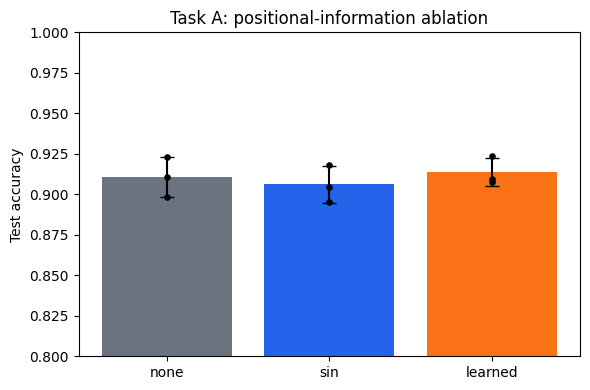

In [11]:
def ms(values, nd=3):
    a = np.asarray(values, dtype=float)
    return fmt(a.mean(), a.std(ddof=1) if len(a) > 1 else 0.0, nd)


rows = []
for pos, label in (("none", "Encoder, no PE"), ("learned", "Encoder, learned PE"), ("sin", "Encoder, sinusoidal PE")):
    r = task_a[pos]
    rows.append(dict(Model=label, Accuracy=ms([x["acc"] for x in r]), MacroF1=ms([x["f1"] for x in r]),
                     Params=r[0]["params"], s_per_epoch=f'{np.mean([x["sec"] for x in r]):.2f}'))

# best Problem 1 model, read from Problem 1's results.csv (if present)
p1_best_acc = None
if P1_RESULTS.exists():
    p1 = pd.read_csv(P1_RESULTS)
    p1 = p1[p1["problem"] == "1-HAR"]
    if len(p1):
        g = p1.groupby("model")
        best = g["test_acc"].mean().idxmax(); d_ = p1[p1["model"] == best]
        p1_best_acc = d_["test_acc"].mean()
        rows.append(dict(Model=f"{best} (Problem 1, best)", Accuracy=ms(d_["test_acc"]),
                         MacroF1=ms(d_["macro_f1"]), Params=int(d_["params"].iloc[0]),
                         s_per_epoch=f'{d_["sec_per_epoch"].mean():.2f}'))
else:
    print("Problem 1 results.csv not found: the Problem 1 row is skipped.")

table_a = pd.DataFrame(rows)
table_a.to_csv("taskA_summary.csv", index=False)
print(table_a.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["none", "sin", "learned"]
means = [np.mean([x["acc"] for x in task_a[p]]) for p in labels]
stds = [np.std([x["acc"] for x in task_a[p]], ddof=1) if len(task_a[p]) > 1 else 0 for p in labels]
ax.bar(labels, means, yerr=stds, capsize=5, color=["#6b7280", "#2563eb", "#f97316"])
for i, p in enumerate(labels):
    ax.scatter([i] * len(task_a[p]), [x["acc"] for x in task_a[p]], color="k", s=14, zorder=3)
if p1_best_acc is not None:
    ax.axhline(p1_best_acc, color="g", ls="--", label="best Problem 1 model")
    ax.legend(frameon=False)
ax.set(ylabel="Test accuracy", title="Task A: positional-information ablation",
       ylim=(min(0.8, min(means) - 0.05), 1.0))
fig.tight_layout(); fig.savefig(FIG_DIR / "taskA_positional_ablation.png", dpi=200); plt.show()

## 4. Task B — character-level causal language model (P2.4)

Tiny Shakespeare, vocabulary from the whole text (65 characters), first 90% train, last 10% validation, no shuffling. Context 128, `d = 128`, 4 heads, 4 layers, FFN 512, dropout 0.1, sinusoidal positions, causal mask, AdamW (1e-3) with a one-cycle schedule, gradient clipping 1.0.

Validation loss is measured on the same fixed set of random windows for every model (fixed generator), so numbers are comparable between runs.

In [12]:
TEXT_PATH = Path("input.txt")      # do not put this file in the submission zip
if not TEXT_PATH.exists():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    TEXT_PATH.write_text(urllib.request.urlopen(url).read().decode("utf-8"), encoding="utf-8")
text = TEXT_PATH.read_text(encoding="utf-8")

chars = sorted(set(text)); V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)
assert V == 65, f"expected 65 characters, got {V}"

data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]            # no shuffling
print(f"{len(text):,} characters | vocab {V} | train {len(train_data):,} | val {len(val_data):,}")
assert decode(encode("First Citizen")) == "First Citizen"


def get_batch(split_data, batch, ctx, gen=None):
    """x: (B, ctx) characters, y: (B, ctx) the same characters shifted by one."""
    ix = torch.randint(len(split_data) - ctx - 1, (batch,), generator=gen).tolist()
    x = torch.stack([split_data[i:i + ctx] for i in ix])
    y = torch.stack([split_data[i + 1:i + ctx + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

1,115,394 characters | vocab 65 | train 1,003,854 | val 111,540


In [13]:
class CharTransformer(nn.Module):
    """idx (B, T) -> token embedding + sinusoidal PE -> N pre-LN blocks -> LN -> logits (B, T, V)."""

    def __init__(self, vocab, d_model=D_LM, n_heads=HEADS_LM, n_layers=LAYERS_LM, d_ff=FF_LM,
                 ctx=CONTEXT, dropout=DROPOUT_LM, causal=True):
        super().__init__()
        self.ctx, self.causal = ctx, causal
        self.tok = nn.Embedding(vocab, d_model)
        self.register_buffer("pe", sinusoidal_pe(ctx, d_model), persistent=False)
        self.register_buffer("causal_mask", torch.tril(torch.ones(ctx, ctx, dtype=torch.bool)), persistent=False)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab)

    def forward(self, idx):
        B, T = idx.shape
        x = self.drop(self.tok(idx) + self.pe[:T])                         # (B, T, d)
        mask = self.causal_mask[:T, :T] if self.causal else None           # True = may attend
        for blk in self.blocks:
            x = blk(x, mask)
        return self.head(self.ln_f(x))                                     # (B, T, V)

    def forward_cached(self, idx, caches, pos):
        """One new token idx: (B, 1) sitting at position `pos`; caches: one (k, v) or None per layer.
        Returns logits (B, 1, V) and the updated caches."""
        assert pos < self.ctx, "absolute positions: the cache only works while the text fits in the context"
        x = self.drop(self.tok(idx) + self.pe[pos:pos + 1])                # (B, 1, d)
        new_caches = []
        for blk, c in zip(self.blocks, caches):
            x, c = blk.forward_cached(x, c)
            new_caches.append(c)
        return self.head(self.ln_f(x)), new_caches


lm = CharTransformer(V).to(DEVICE).eval()
expected = V * D_LM + LAYERS_LM * 198_272 + 2 * D_LM + (D_LM * V + V)      # embed + blocks + final LN + head
assert count_params(lm) == expected, (count_params(lm), expected)
print("language model parameters:", f"{count_params(lm):,}")

xt = torch.randint(0, V, (2, 20), device=DEVICE); xt2 = xt.clone(); xt2[:, -1] = (xt2[:, -1] + 1) % V
with torch.no_grad():
    a, b = lm(xt), lm(xt2)
assert a.shape == (2, 20, V)
assert (a[:, :-1] - b[:, :-1]).abs().max() < 1e-5, "changing the last token must not change earlier logits"
print("language-model tests passed.")

language model parameters: 810,049
language-model tests passed.


  iter   250 | train 2.671 | val 2.691
  iter   500 | train 2.438 | val 2.447
  iter   750 | train 2.174 | val 2.201
  iter  1000 | train 1.969 | val 2.050
  iter  1250 | train 1.778 | val 1.902
  iter  1500 | train 1.666 | val 1.833
  iter  1750 | train 1.584 | val 1.759
  iter  2000 | train 1.524 | val 1.702
  iter  2250 | train 1.489 | val 1.683
  iter  2500 | train 1.454 | val 1.648
  iter  2750 | train 1.430 | val 1.624
  iter  3000 | train 1.407 | val 1.609
  iter  3250 | train 1.391 | val 1.599
  iter  3500 | train 1.375 | val 1.584
  iter  3750 | train 1.363 | val 1.573
  iter  4000 | train 1.354 | val 1.565
  iter  4250 | train 1.347 | val 1.560
  iter  4500 | train 1.343 | val 1.555
  iter  4750 | train 1.340 | val 1.553
  iter  5000 | train 1.340 | val 1.553

final validation loss 1.549 nats = 2.235 bits/char (uniform guess: ln 65 = 4.174); train time 182s


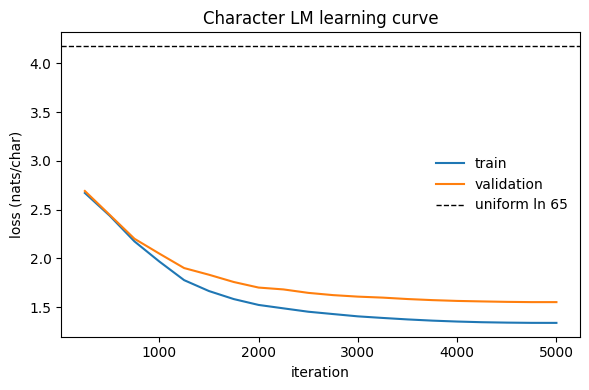

In [14]:
@torch.no_grad()
def eval_split(model, split_data, n_batches, seed=1234):
    """Mean cross-entropy (nats/char) on a FIXED set of random windows (same for every model)."""
    model.eval(); gen = torch.Generator().manual_seed(seed); total = 0.0
    for _ in range(n_batches):
        xb, yb = get_batch(split_data, LM_BATCH, CONTEXT, gen)
        logits = model(xb)
        total += F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1)).item()
    return total / n_batches


def train_lm(model, iters, eval_every=EVAL_EVERY, lr=LM_LR):
    """AdamW + one-cycle schedule + grad clipping. Returns curve [(iter, train, val)] and seconds."""
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=iters)
    curve = []; sync(); t0 = time.perf_counter()
    for it in range(1, iters + 1):
        model.train()
        xb, yb = get_batch(train_data, LM_BATCH, CONTEXT)
        logits = model(xb)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
        opt.zero_grad(set_to_none=True); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        opt.step(); sched.step()
        if it % eval_every == 0 or it == iters:
            curve.append((it, eval_split(model, train_data, EVAL_BATCHES), eval_split(model, val_data, EVAL_BATCHES)))
            print(f"  iter {it:5d} | train {curve[-1][1]:.3f} | val {curve[-1][2]:.3f}")
    sync()
    return curve, time.perf_counter() - t0


def log_lm(problem, name, seed, model, val_nats, secs, notes=""):
    append_result(dict(problem=problem, model=name, seed=seed, params=count_params(model),
                       val_loss_nats=val_nats, bits_per_char=val_nats / math.log(2),
                       notes=f"train_seconds={secs:.0f};{notes}"))


# ---------------- main run ----------------
seed_everything(SEEDS[0])
main_lm = CharTransformer(V)
main_curve, main_secs = train_lm(main_lm, LM_ITERS)
main_val = eval_split(main_lm, val_data, FINAL_EVAL_BATCHES)
print(f"\nfinal validation loss {main_val:.3f} nats = {main_val / math.log(2):.3f} bits/char "
      f"(uniform guess: ln 65 = {math.log(V):.3f}); train time {main_secs:.0f}s")
log_lm("2-B-LM", "Transformer", SEEDS[0], main_lm, main_val, main_secs,
       f"d={D_LM};heads={HEADS_LM};layers={LAYERS_LM};ctx={CONTEXT};iters={LM_ITERS};batch={LM_BATCH}")

c = np.array(main_curve)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(c[:, 0], c[:, 1], label="train"); ax.plot(c[:, 0], c[:, 2], label="validation")
ax.axhline(math.log(V), color="k", ls="--", lw=1, label="uniform ln 65")
ax.set(xlabel="iteration", ylabel="loss (nats/char)", title="Character LM learning curve")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / "lm_learning_curve.png", dpi=200); plt.show()

In [15]:
@torch.no_grad()
def generate(model, n_new=N_SAMPLE, temperature=1.0, top_k=TOP_K, seed=0, start="\n"):
    """Plain generation: re-runs the model on the last ctx characters at every step.
    Returns exactly n_new characters (the start character is not included)."""
    model.eval(); torch.manual_seed(seed)
    ctx = getattr(model, "ctx", CONTEXT)
    idx = torch.tensor([[stoi[start]]], device=DEVICE)
    for _ in range(n_new):
        cond = idx[:, -ctx:]                                       # crop to the context window
        logits = model(cond)[:, -1, :] / temperature               # (1, V) for the last position
        if top_k is not None:
            kth = torch.topk(logits, top_k).values[:, [-1]]
            logits = logits.masked_fill(logits < kth, float("-inf"))   # keep only the top-k characters
        nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
        idx = torch.cat([idx, nxt], dim=1)
    return decode(idx[0, 1:].tolist())


with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for T_ in TEMPERATURES:
        s = generate(main_lm, temperature=T_, seed=0)
        assert len(s) == N_SAMPLE, "each sample must be exactly 500 characters"
        f.write(f"===== temperature {T_}, top-k {TOP_K}, {N_SAMPLE} characters =====\n{s}\n\n")
        print(f"===== temperature {T_} =====\n{s[:400]}\n")
print("saved generated_samples.txt")

===== temperature 0.2 =====


AUTOLYCUS:
I will be so so death, that we have sent the state,
And the shall be the senate of the season of the senses
That the state of the company of the season of the country
That thou wilt be so so the secret of the sea
And should be the sound of the senators.

Second Murderer:
The had been and the lady of the world,
And see the state of my brother and all the people
That the sun of the deat

===== temperature 0.8 =====
Put you not like more absent you call death?

FRIAR LAURENCE:
This consul be foul dear our horse. I have it is the noble.
Why thranger me of this slistering what we blood
That will the law--backless what thou how your true;
And less he is like alone: he was he daughter?

FRIAR LAURENCE:
My sirion, and all to the else him and done;
But are I belmisely friends and name me by him?

KING RICHARD III:


===== temperature 1.5 =====
Purgy him eavy and impossibity.
Dy ithdrumbli welconce. 'WIs want
which rebury?

GLOUCESTER:
Coriolate; wim the 

In [16]:
# Numbers to support the written discussion of the three temperatures (P2.4)
train_words = set(text[:n_train].split())
rows = []
for T_ in TEMPERATURES:
    s = generate(main_lm, temperature=T_, seed=0)
    words = s.split()
    grams = [s[i:i + 20] for i in range(len(s) - 19)]
    rows.append(dict(Temperature=T_,
                     Distinct_words=round(len(set(words)) / len(words), 3),            # variety of words
                     Real_words=round(float(np.mean([w in train_words for w in words])), 3),  # spelled like training words
                     Repeated_20grams=round(1 - len(set(grams)) / len(grams), 3)))     # repetition of long strings
sample_stats = pd.DataFrame(rows); sample_stats.to_csv("sample_stats.csv", index=False)
print(sample_stats.to_string(index=False))

 Temperature  Distinct_words  Real_words  Repeated_20grams
         0.2           0.486       0.981             0.006
         0.8           0.776       0.929             0.000
         1.5           0.938       0.500             0.000


## 5. Analysis and ablations (P2.5)

### (a) Attention heatmaps
Last layer of the trained model on one sentence. I automatically pick the head with the most weight on the previous character (the most local one) and the head with the highest entropy (the widest one), and print the statistics for all heads so the choice can be justified in the report.

head 1: mean weight on previous char 0.151 | mean entropy 2.022
head 2: mean weight on previous char 0.323 | mean entropy 1.304
head 3: mean weight on previous char 0.319 | mean entropy 1.423
head 4: mean weight on previous char 0.193 | mean entropy 1.834


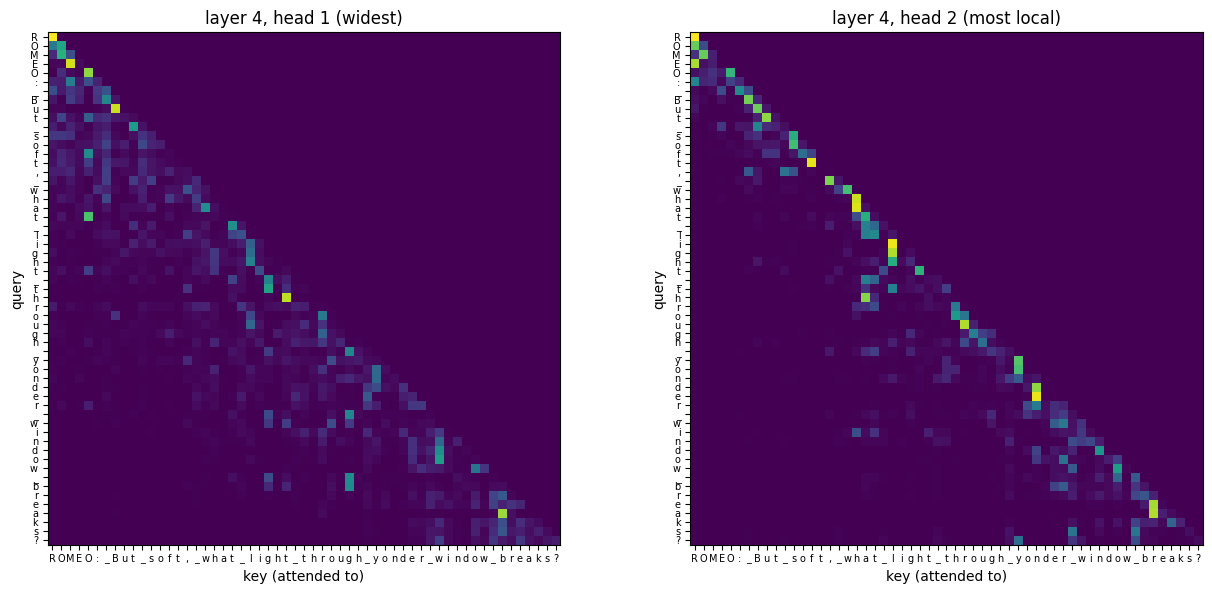

In [17]:
sentence = "ROMEO: But soft, what light through yonder window breaks?"
assert all(c in stoi for c in sentence), "a character of the sentence is not in the vocabulary"
ids = torch.tensor([encode(sentence)], device=DEVICE)

attn_layer = main_lm.blocks[-1].attn
attn_layer.keep_attn = True
with torch.no_grad():
    main_lm.eval(); main_lm(ids)
attn = attn_layer.last_attn[0].cpu()                    # (heads, T, T)
attn_layer.keep_attn = False
Tn = attn.size(-1)

prev_w = torch.stack([attn[:, t, t - 1] for t in range(1, Tn)], dim=1).mean(1)       # weight on previous char
entropy = -(attn.clamp_min(1e-9).log() * attn).sum(-1).mean(-1)                        # mean row entropy (nats)
for hh in range(attn.size(0)):
    print(f"head {hh + 1}: mean weight on previous char {prev_w[hh]:.3f} | mean entropy {entropy[hh]:.3f}")

h_local = int(prev_w.argmax())
h_wide = next(int(i) for i in entropy.argsort(descending=True) if int(i) != h_local)
labels = ["_" if ch == " " else ch for ch in sentence]
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for axx, hh, kind in zip(axes, (h_wide, h_local), ("widest", "most local")):
    axx.imshow(attn[hh].numpy(), cmap="viridis")
    axx.set_xticks(range(Tn)); axx.set_xticklabels(labels, fontsize=7)
    axx.set_yticks(range(Tn)); axx.set_yticklabels(labels, fontsize=7)
    axx.set(title=f"layer {LAYERS_LM}, head {hh + 1} ({kind})", xlabel="key (attended to)", ylabel="query")
fig.tight_layout(); fig.savefig(FIG_DIR / "attention_heatmaps.png", dpi=200); plt.show()

### (b) Number of heads at fixed d = 128, and (c) removing the causal mask
Same seed and the same iteration budget for every variant. The 4-head causal run doubles as the reference for part (c). Without the causal mask, validation loss is also measured with the mask removed (teacher forcing), so it is leaking in the same way as training. Generation is where the damage becomes visible.

--- heads = 1 (d_k = 128) ---
  iter   250 | train 2.444 | val 2.446
  iter   500 | train 2.016 | val 2.086
  iter   750 | train 1.796 | val 1.921
  iter  1000 | train 1.687 | val 1.834
  iter  1250 | train 1.638 | val 1.799
  iter  1500 | train 1.629 | val 1.795
--- heads = 4 (d_k = 32) ---
  iter   250 | train 2.473 | val 2.477
  iter   500 | train 2.054 | val 2.111
  iter   750 | train 1.823 | val 1.947
  iter  1000 | train 1.698 | val 1.842
  iter  1250 | train 1.647 | val 1.802
  iter  1500 | train 1.637 | val 1.796
--- heads = 8 (d_k = 16) ---
  iter   250 | train 2.475 | val 2.482
  iter   500 | train 2.063 | val 2.118
  iter   750 | train 1.826 | val 1.947
  iter  1000 | train 1.712 | val 1.856
  iter  1250 | train 1.659 | val 1.813
  iter  1500 | train 1.647 | val 1.808
 Heads  Val_loss_nats  Bits_per_char
     1          1.794          2.588
     4          1.795          2.590
     8          1.806          2.605


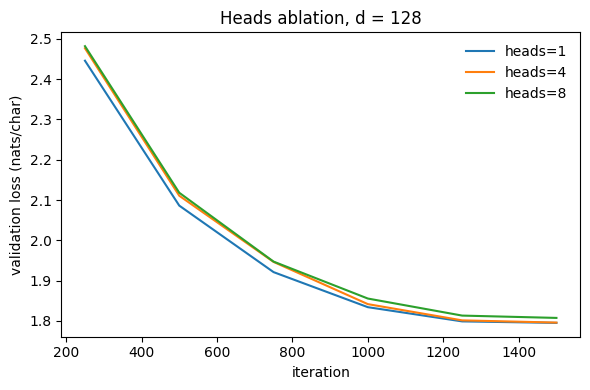

In [18]:
abl_curves, abl_final = {}, {}
for heads in (1, 4, 8):
    print(f"--- heads = {heads} (d_k = {D_LM // heads}) ---")
    seed_everything(SEEDS[0])
    m = CharTransformer(V, n_heads=heads)
    curve, secs = train_lm(m, ABL_ITERS)
    val = eval_split(m, val_data, FINAL_EVAL_BATCHES)
    abl_curves[heads], abl_final[heads] = curve, val
    log_lm("2-heads-ablation", f"heads={heads}", SEEDS[0], m, val, secs,
           f"d={D_LM};d_k={D_LM // heads};iters={ABL_ITERS}")
    if heads == 4:
        causal_model = m

heads_table = pd.DataFrame([dict(Heads=h_, Val_loss_nats=round(v, 3), Bits_per_char=round(v / math.log(2), 3))
                            for h_, v in abl_final.items()])
heads_table.to_csv("heads_ablation.csv", index=False); print(heads_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
for h_, cv in abl_curves.items():
    cv = np.array(cv); ax.plot(cv[:, 0], cv[:, 2], label=f"heads={h_}")
ax.set(xlabel="iteration", ylabel="validation loss (nats/char)", title=f"Heads ablation, d = {D_LM}")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / "heads_ablation.png", dpi=200); plt.show()

--- no causal mask (4 heads) ---
  iter   250 | train 2.471 | val 2.476
  iter   500 | train 0.057 | val 0.072
  iter   750 | train 0.022 | val 0.024
  iter  1000 | train 0.020 | val 0.021
  iter  1250 | train 0.019 | val 0.020
  iter  1500 | train 0.019 | val 0.020


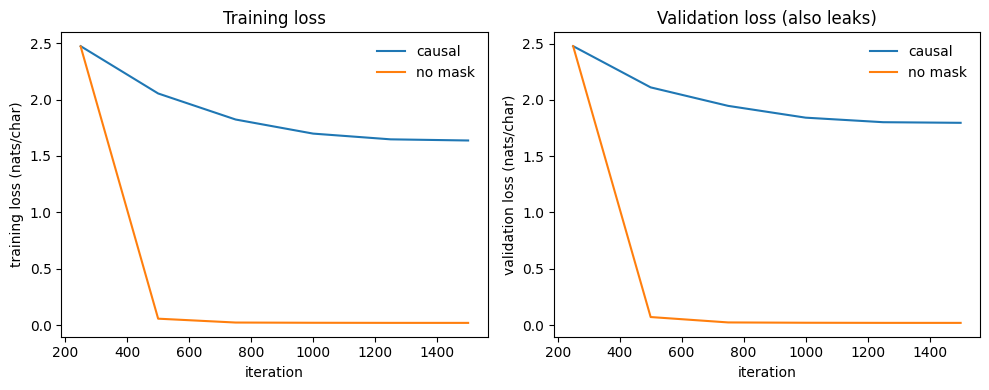

final training loss: causal 1.637 | no mask 0.019
final validation loss: causal 1.795 | no mask 0.020

--- generation from the NO-MASK model (T=0.8), first 300 characters ---
'\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n ar\n\n\n\n\nTere,\nar\n\n\n\n\nheoure ald,\n\nThisrd\nHe ar'
newline fraction: 0.893


344

In [19]:
print("--- no causal mask (4 heads) ---")
seed_everything(SEEDS[0])
nomask_model = CharTransformer(V, causal=False)
nomask_curve, nomask_secs = train_lm(nomask_model, ABL_ITERS)
nomask_val = eval_split(nomask_model, val_data, FINAL_EVAL_BATCHES)
log_lm("2-nomask", "no-causal-mask", SEEDS[0], nomask_model, nomask_val, nomask_secs,
       f"heads=4;iters={ABL_ITERS};validation also leaks (mask removed)")

a, b = np.array(abl_curves[4]), np.array(nomask_curve)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(a[:, 0], a[:, 1], label="causal"); axes[0].plot(b[:, 0], b[:, 1], label="no mask")
axes[0].set(xlabel="iteration", ylabel="training loss (nats/char)", title="Training loss"); axes[0].legend(frameon=False)
axes[1].plot(a[:, 0], a[:, 2], label="causal"); axes[1].plot(b[:, 0], b[:, 2], label="no mask")
axes[1].set(xlabel="iteration", ylabel="validation loss (nats/char)", title="Validation loss (also leaks)")
axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "no_mask.png", dpi=200); plt.show()

print(f"final training loss: causal {a[-1, 1]:.3f} | no mask {b[-1, 1]:.3f}")
print(f"final validation loss: causal {abl_final[4]:.3f} | no mask {nomask_val:.3f}")
sample_nm = generate(nomask_model, n_new=300, temperature=0.8, seed=0)
print("\n--- generation from the NO-MASK model (T=0.8), first 300 characters ---")
print(repr(sample_nm[:300]))
print("newline fraction:", round(sample_nm.count("\n") / len(sample_nm), 3))
Path("nomask_sample.txt").write_text(f"no causal mask (ablation), temperature 0.8\n{sample_nm}\n", encoding="utf-8")  # kept out of generated_samples.txt

### (d) Time and memory against context length
Same model (d = 128, 4 heads, 4 layers), batch 16, random tokens, forward + backward + AdamW step. Peak memory is `torch.cuda.max_memory_allocated` after warm-up, so it includes weights, optimiser state and activations. On a CPU-only machine memory is not measured.

n =   64 |    18.2 ms/step | peak    100.6 MB
n =  128 |    16.0 ms/step | peak    164.9 MB
n =  256 |    21.1 ms/step | peak    348.7 MB
n =  512 |    60.8 ms/step | peak    969.5 MB
64 -> 128: time x0.88, memory x1.64 (quadratic would be x4)
128 -> 256: time x1.32, memory x2.11 (quadratic would be x4)
256 -> 512: time x2.88, memory x2.78 (quadratic would be x4)
log-log slope of time for n >= 128: 0.96
log-log slope of memory for n >= 128: 1.28


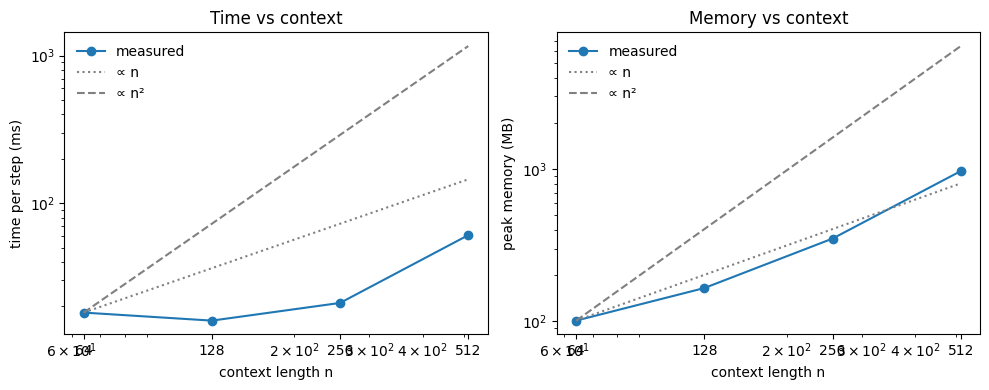

In [20]:
def measure_context(n, batch=TIMING_BATCH, steps=TIMING_STEPS, warmup=TIMING_WARMUP):
    seed_everything(0)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    model = CharTransformer(V, ctx=n).to(DEVICE).train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    x = torch.randint(0, V, (batch, n), device=DEVICE); y = torch.randint(0, V, (batch, n), device=DEVICE)

    def step():
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()

    for _ in range(warmup):
        step()
    sync()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()                 # weights + optimiser state stay counted
    t0 = time.perf_counter()
    for _ in range(steps):
        step()
    sync()
    ms_step = (time.perf_counter() - t0) / steps * 1000
    peak = torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE.type == "cuda" else float("nan")
    del model, opt, x, y
    return ms_step, peak


timing = []
for n in CONTEXT_SIZES:
    t_ms, mem = measure_context(n)
    timing.append((n, t_ms, mem))
    print(f"n = {n:4d} | {t_ms:7.1f} ms/step | peak {mem:8.1f} MB")
    append_result(dict(problem="2-context", model="Transformer", seed=0, seq_len=n, params=count_params(CharTransformer(V, ctx=n)),
                       notes=f"ms_per_step={t_ms:.1f};peak_MB={mem:.1f};batch={TIMING_BATCH}"))

ns = np.array([t[0] for t in timing], float); tms = np.array([t[1] for t in timing]); mem = np.array([t[2] for t in timing])
for i in range(1, len(ns)):
    print(f"{int(ns[i-1])} -> {int(ns[i])}: time x{tms[i] / tms[i-1]:.2f}, memory x{mem[i] / mem[i-1]:.2f} (quadratic would be x4)")
slope_t = np.polyfit(np.log(ns[1:]), np.log(tms[1:]), 1)[0]
print(f"log-log slope of time for n >= 128: {slope_t:.2f}")
if not np.isnan(mem).any():
    print(f"log-log slope of memory for n >= 128: {np.polyfit(np.log(ns[1:]), np.log(mem[1:]), 1)[0]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axx, vals, ylabel, title in ((axes[0], tms, "time per step (ms)", "Time vs context"),
                                 (axes[1], mem, "peak memory (MB)", "Memory vs context")):
    axx.loglog(ns, vals, "o-", label="measured")
    axx.loglog(ns, vals[0] * ns / ns[0], ":", color="gray", label="∝ n")
    axx.loglog(ns, vals[0] * (ns / ns[0]) ** 2, "--", color="gray", label="∝ n²")
    axx.set(xlabel="context length n", ylabel=ylabel, title=title); axx.set_xticks(ns); axx.set_xticklabels(ns.astype(int))
    axx.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "context_scaling.png", dpi=200); plt.show()

## 6. Bonus (up to 5 points)

### 6a. Key-value cache for generation
Without a cache, every new character re-runs all layers on the whole window: cost per step grows like $O(T\,d^2 + T^2 d)$. With a cache, each layer stores the keys and values of the past (`(B, h, T, d_k)` each), so a step only processes the one new token: $O(T\,d + d^2)$. The cache costs $2 \cdot L \cdot T \cdot d$ floats per sequence.

**Limit of my implementation.** The model uses absolute positional encodings and a 128-character window. Once the text is longer than the window, every position shifts at each step, so a cache cannot be reused. The cache is therefore used for up to `ctx - 1` new characters; the 500-character samples above use the plain sliding window. The benchmark below uses `ctx - 1` new characters at context 128 (trained model) and 256 and 512 (untrained models, timing only).

In [21]:
@torch.no_grad()
def generate_cached(model, n_new, temperature=1.0, top_k=TOP_K, seed=0, start="\n"):
    """Same sampling as generate(), but each step feeds ONE token and reuses cached keys/values."""
    assert n_new + 1 <= model.ctx, "the cache is only valid while the text fits in the context window"
    model.eval(); torch.manual_seed(seed)
    tok = torch.tensor([[stoi[start]]], device=DEVICE)
    caches, out = [None] * len(model.blocks), []
    for pos in range(n_new):
        logits, caches = model.forward_cached(tok, caches, pos)     # (1, 1, V)
        logits = logits[:, -1, :] / temperature
        if top_k is not None:
            kth = torch.topk(logits, top_k).values[:, [-1]]
            logits = logits.masked_fill(logits < kth, float("-inf"))
        tok = torch.multinomial(torch.softmax(logits, dim=-1), 1)
        out.append(tok.item())
    return decode(out)


# ---------- test 1: step-by-step cached logits equal one full forward pass ----------
main_lm.eval()
seq = torch.randint(0, V, (2, CONTEXT), device=DEVICE)
with torch.no_grad():
    full = main_lm(seq)                                              # (2, CONTEXT, V)
    caches, steps = [None] * LAYERS_LM, []
    for p in range(CONTEXT):
        lg, caches = main_lm.forward_cached(seq[:, p:p + 1], caches, p)
        steps.append(lg)
    cached = torch.cat(steps, dim=1)
err = (full - cached).abs().max().item()
assert err < 1e-4, f"cached logits differ from the full forward pass: {err}"
print(f"cached logits match the full forward pass (max |diff| = {err:.2e})")

# ---------- test 2: same seed gives the same text ----------
t_plain = generate(main_lm, n_new=CONTEXT - 1, temperature=0.8, seed=0)
t_cache = generate_cached(main_lm, CONTEXT - 1, temperature=0.8, seed=0)
print("identical sampled text with and without cache:", t_plain == t_cache)

cached logits match the full forward pass (max |diff| = 8.23e-06)
identical sampled text with and without cache: True


 Context  New_chars  Plain_s  Cached_s  Speedup  Cached_chars_per_s
     128        127     0.43      0.37      1.1                 339
     256        255     0.92      0.75      1.2                 339
     512        511     1.87      1.50      1.3                 342


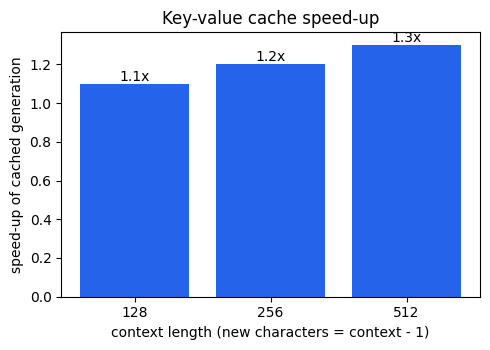

In [22]:
def best_time(fn, repeats=2):
    fn(8); sync()                                   # warm-up on a short run
    best = float("inf")
    for _ in range(repeats):
        sync(); t0 = time.perf_counter(); fn(None); sync()
        best = min(best, time.perf_counter() - t0)
    return best


KV_CONTEXTS = (128,) if QUICK_TEST else (128, 256, 512)
kv_rows = []
for n_ctx in KV_CONTEXTS:
    if n_ctx == CONTEXT:
        m = main_lm
    else:
        seed_everything(0); m = CharTransformer(V, ctx=n_ctx).to(DEVICE).eval()     # untrained: timing only
    n_new = n_ctx - 1
    t_plain = best_time(lambda n, m=m, n_new=n_new: generate(m, n_new=n or n_new, temperature=0.8, seed=0))
    t_cache = best_time(lambda n, m=m, n_new=n_new: generate_cached(m, n or n_new, temperature=0.8, seed=0))
    kv_rows.append(dict(Context=n_ctx, New_chars=n_new, Plain_s=round(t_plain, 2), Cached_s=round(t_cache, 2),
                        Speedup=round(t_plain / t_cache, 1), Cached_chars_per_s=round(n_new / t_cache)))
    for name, t_ in (("Transformer-nocache", t_plain), ("Transformer-kvcache", t_cache)):
        append_result(dict(problem="2-bonus-kvcache", model=name, seed=0, seq_len=n_ctx, params=count_params(m),
                           notes=f"new_chars={n_new};seconds={t_:.2f};chars_per_s={n_new / t_:.0f};"
                                 f"{'trained' if m is main_lm else 'untrained, timing only'}"))
kv_table = pd.DataFrame(kv_rows); kv_table.to_csv("bonus_kv_cache.csv", index=False)
print(kv_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar([str(c) for c in kv_table["Context"]], kv_table["Speedup"], color="#2563eb")
for i, s_ in enumerate(kv_table["Speedup"]):
    ax.text(i, s_, f"{s_}x", ha="center", va="bottom")
ax.set(xlabel="context length (new characters = context - 1)", ylabel="speed-up of cached generation",
       title="Key-value cache speed-up")
fig.tight_layout(); fig.savefig(FIG_DIR / "kv_cache_speedup.png", dpi=200); plt.show()

### 6b. LSTM versus Transformer on the character task
2-layer LSTM with 128 units, same data, same 5,000-iteration budget, batch, optimiser, schedule and clipping, 3 seeds each. The Transformer seed-1 run is reused from Section 4.

In [23]:
class CharLSTM(nn.Module):
    def __init__(self, vocab, d=128, layers=2, dropout=DROPOUT_LM):
        super().__init__()
        self.emb = nn.Embedding(vocab, d)
        self.lstm = nn.LSTM(d, d, num_layers=layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(d, vocab)

    def forward(self, idx):                                   # (B, T) -> (B, T, V)
        out, _ = self.lstm(self.emb(idx))
        return self.head(out)


bonus = {"Transformer": [], "LSTM": []}
for seed in RUN_SEEDS:
    for name in ("Transformer", "LSTM"):
        if name == "Transformer" and seed == SEEDS[0]:
            bonus[name].append((main_val, main_secs, count_params(main_lm)))      # reuse the main run
            log_lm("2-B-LM-bonus", name, seed, main_lm, main_val, main_secs, "reused main run")
            continue
        print(f"--- {name}, seed {seed} ---")
        seed_everything(seed)
        m = CharTransformer(V) if name == "Transformer" else CharLSTM(V)
        _, secs = train_lm(m, LM_ITERS)
        val = eval_split(m, val_data, FINAL_EVAL_BATCHES)
        bonus[name].append((val, secs, count_params(m)))
        log_lm("2-B-LM-bonus", name, seed, m, val, secs, f"iters={LM_ITERS}")

rows = []
for name, r in bonus.items():
    vals = np.array([x[0] for x in r]); secs = np.array([x[1] for x in r])
    rows.append(dict(Model=name, Val_loss_nats=fmt(vals.mean(), vals.std(ddof=1) if len(vals) > 1 else 0.0),
                     Bits_per_char=fmt(vals.mean() / math.log(2), (vals.std(ddof=1) if len(vals) > 1 else 0.0) / math.log(2)),
                     Params=r[0][2], Train_seconds=f"{secs.mean():.0f}"))
bonus_table = pd.DataFrame(rows); bonus_table.to_csv("bonus_lstm_vs_transformer.csv", index=False)
print(bonus_table.to_string(index=False))

--- LSTM, seed 1 ---
  iter   250 | train 3.259 | val 3.290
  iter   500 | train 2.614 | val 2.612
  iter   750 | train 2.167 | val 2.183
  iter  1000 | train 1.919 | val 1.979
  iter  1250 | train 1.760 | val 1.862
  iter  1500 | train 1.659 | val 1.788
  iter  1750 | train 1.596 | val 1.743
  iter  2000 | train 1.550 | val 1.707
  iter  2250 | train 1.515 | val 1.685
  iter  2500 | train 1.491 | val 1.665
  iter  2750 | train 1.472 | val 1.654
  iter  3000 | train 1.456 | val 1.640
  iter  3250 | train 1.444 | val 1.629
  iter  3500 | train 1.434 | val 1.620
  iter  3750 | train 1.426 | val 1.615
  iter  4000 | train 1.421 | val 1.612
  iter  4250 | train 1.418 | val 1.609
  iter  4500 | train 1.416 | val 1.607
  iter  4750 | train 1.415 | val 1.606
  iter  5000 | train 1.415 | val 1.606
--- Transformer, seed 42 ---
  iter   250 | train 2.663 | val 2.676
  iter   500 | train 2.446 | val 2.450
  iter   750 | train 2.189 | val 2.216
  iter  1000 | train 1.970 | val 2.053
  iter  1250 |

## Submission checks
Asserts that the required outputs exist and have the required format.

In [24]:
import re

# generated_samples.txt: three labelled samples of exactly 500 characters, at temperature 0.2, 0.8 and 1.5
raw = Path("generated_samples.txt").read_text(encoding="utf-8")
parts = re.split(r"===== temperature ([0-9.]+), top-k \d+, 500 characters =====\n", raw)
blocks = [(parts[i], parts[i + 1][:-2]) for i in range(1, len(parts), 2)]      # drop the 2 separator newlines
assert [float(t) for t, _ in blocks] == list(TEMPERATURES), "need one labelled sample per temperature"
assert all(len(s) == N_SAMPLE for _, s in blocks), "every sample must be exactly 500 characters"

# results.csv: exactly the required columns
header = pd.read_csv(RESULTS_PATH, nrows=0).columns.tolist()
assert header == RESULT_COLUMNS, header

# required figures
need = ["attention_heatmaps", "lm_learning_curve", "heads_ablation", "no_mask", "context_scaling", "taskA_positional_ablation"]
missing = [n for n in need if not (FIG_DIR / f"{n}.png").exists()]
assert not missing, f"missing figures: {missing}"
print("all submission checks passed")

all submission checks passed


## Done

In [25]:
print(f"results written to {RESULTS_PATH.resolve()}")
print("figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))
print("also saved: generated_samples.txt, nomask_sample.txt, sample_stats.csv, taskA_summary.csv, heads_ablation.csv, bonus_kv_cache.csv, bonus_lstm_vs_transformer.csv")
print(f"total notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes on {DEVICE}")

results written to /results.csv
figures: ['attention_heatmaps.png', 'context_scaling.png', 'heads_ablation.png', 'kv_cache_speedup.png', 'lm_learning_curve.png', 'no_mask.png', 'taskA_positional_ablation.png']
also saved: generated_samples.txt, nomask_sample.txt, sample_stats.csv, taskA_summary.csv, heads_ablation.csv, bonus_kv_cache.csv, bonus_lstm_vs_transformer.csv
total notebook run time: 18.2 minutes on cuda
